In [32]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [33]:
# The class name can be anything: State, GraphState, GS, MyState...
# It describes what data flows through the graph.
class State(TypedDict):
    # Annotated[list, add_messages] means:
    #   list         -> the type of this field
    #   add_messages -> append new messages; replace messages with matching IDs
    # Without add_messages, a node's returned messages would REPLACE the old ones.
    messages: Annotated[list, add_messages]

In [34]:
# Creating some dummy nodes that will perform operations on the messages in the state. In a real application, these would be more complex and meaningful.


def Step1(state: State) -> State:  # previous state passed to it.
    # This step appends a message to the state's messages list.
    return {
        "messages": ["Step 1 completed."]
    }  # new state returned, which will be merged with the previous state. using the reducer add_messages, the new message will be appended to the old list.

In [35]:
def Step2(state: State) -> State:
    return {"messages": ["Step 2 completed."]}

### Start the graph assembly

In [ ]:
builder = StateGraph(
    State
)  # The StateGraph class is initialized with the State TypedDict, which defines the structure of the state that will be passed through the graph. This allows the graph to manage and update the state as it processes each node.

builder.add_node(
    "STEP ONE", Step1
)  # The add_node method is called to add the Step1 function as a node in the graph. The first argument gives the node its name; the second supplies the function it runs.
builder.add_node(
    "STEP TWO", Step2
)  # Register Step2 under the exact name used by the edges.


### Connecting the Graph

In [ ]:
builder.add_edge(
    START, "STEP ONE"
)  # The add_edge method is used to define the flow of the graph. Here, an edge is added from the START node to the "STEP ONE" node, indicating that STEP ONE should be executed first.
builder.add_edge(
    "STEP ONE", "STEP TWO"
)  # Another edge is added from "STEP ONE" to "STEP TWO", indicating that STEP TWO should be executed after STEP ONE.
builder.add_edge(
    "STEP TWO", END
)  # Finally, an edge is added from "STEP TWO" to the END node, indicating that the graph processing should end after STEP TWO


### Compiling the graph 

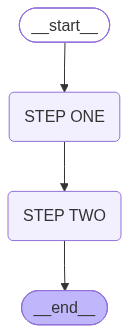

In [ ]:
graph = builder.compile()  # The compile method is called to finalize the graph structure and prepare it for execution. This checks the graph structure and creates the runnable graph; it does not execute our nodes.

graph  # in a Jupyter notebook, this will display the graph structure visually, allowing you to see the nodes and edges that have been defined.

## Working with the graph

### Invoking the Graph

In [ ]:
response = graph.invoke(
    {"messages": ["Starting Message"]}
)  # The invoke method is called to execute the graph. with a starting state that contains an initial message. The graph will process each node in the order defined by the edges, updating the state as it goes.

response


{'messages': [HumanMessage(content='Starting Message', additional_kwargs={}, response_metadata={}, id='fc384e80-5201-4506-bf30-d581ae8b9086'),
  HumanMessage(content='Step 1 completed.', additional_kwargs={}, response_metadata={}, id='63341a06-83ac-4f8c-a73d-4d85d3083c11'),
  HumanMessage(content='Step 2 completed.', additional_kwargs={}, response_metadata={}, id='857c03b5-f744-47de-a0e5-fd36d0f5a845')]}